## SI Figures for capex and opex of each plant

In [20]:
file ='../Figures'

import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import math as math


#import csv file as a dictionary
path = '../Input_Data/BACWA_all_plants.csv'
LSB = pd.read_csv(path)

In [21]:
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

tags = ['BACWA_Current_conc',	'Average_TIN_Dry_BACWA_projected (lb N/day)',	'Average_Flow_Dry_BACWA_current',	'Average_Flow_Dry_BACWA_projected',
        'Opex_min_L2',	'Opex_max_L2',	'Opex_avg_dry_L2',	'Opex_avg_year_L2',	'Opex_dry_mil_L2',	'Opex_year_mil_L2',
        'Opex_min_L3',	'Opex_max_L3',	'Opex_avg_dry_L3',	'Opex_avg_year_L3',	'Opex_dry_mil_L3',	'Opex_year_mil_L3']

lab = ['(a)', '(b)', '(c)']

def plot_opex_WWTP(WWTP, i):
        df = LSB[LSB['Abbreviation'] == WWTP]
        # L2 tags
        opex_min_L2 = df[tags[4]]
        opex_max_L2 = df[tags[5]]
        opex_avg_L2 = [df[tags[6]], df[tags[7]]]
        opex_mil_L2 = [df[tags[8]], df[tags[9]]]

        # L3 tags
        opex_min_L3 = df[tags[10]]
        opex_max_L3 = df[tags[11]]
        opex_avg_L3 = [df[tags[12]], df[tags[13]]]
        opex_mil_L3 = [df[tags[14]], df[tags[15]]]

        # create figure
        fig, ax = plt.subplots(1,1, figsize=(120/25.4, 70/25.4))

        # plot data points
        plt.scatter(opex_avg_L2, opex_mil_L2, color='black', label='L2 average opex', marker='o', s=25)
        plt.scatter(opex_avg_L3, opex_mil_L3, color='red', label='L3 average opex', marker='x', s=25)

        # find best fit linear line 
        # create new list that contains both opex_avg_L2 and opex_avg_L3
        opex_avg = []
        opex_mil = []
        opex_bound = []
        
        for j in range(2):
                opex_avg.append(opex_avg_L2[j].item())
                opex_mil.append(opex_mil_L2[j].item())
        for j in range(2):
                opex_avg.append(opex_avg_L3[j].item())
                opex_mil.append(opex_mil_L3[j].item())
        opex_bound.append(opex_min_L2.iloc[0])
        opex_bound.append(opex_max_L3.iloc[0])
                
        
        z = np.polyfit(opex_avg, opex_mil, 1)
        p = np.poly1d(z)
        plt.plot(opex_bound, p(opex_bound), color='black', linestyle='--', linewidth=1, label='Line of best fit')
        
        #calculate R2
        r2 = np.corrcoef(opex_mil, p(opex_avg))[0, 1]**2

        #calculate RMSE
        rmse = np.sqrt(np.mean((p(opex_avg) - opex_mil)**2))*100
        
        
        # plot vertical line at opex_min and opex_max
        # plot vertical line at opex_min and opex_max
        plt.vlines(opex_min_L2, ymin=0, ymax= p(opex_min_L2.iloc[0]), color='black', linestyle='dashdot', label='bounds of L2 operation', linewidth= line_wid)
        plt.vlines(opex_max_L2, ymin=0, ymax= p(opex_max_L2.iloc[0]), color='black', linestyle='dashdot',linewidth= line_wid)

        plt.vlines(opex_min_L3, ymin=0, ymax=p(opex_min_L3.iloc[0]), color='red', linestyle='dashdot', label='bounds of L3 operation',linewidth= line_wid)
        plt.vlines(opex_max_L3, ymin=0, ymax=p(opex_max_L3.iloc[0]), color='red', linestyle='dashdot', linewidth= line_wid)

        ax.set_xlabel('TIN removed \n(lb N/day)', **hfont)
        ax.set_ylabel('Opex \n(mil $/year)', **hfont)
        ax.set_title(lab[i] + ' ' + WWTP, **hfont)
        min_x = math.floor(opex_min_L2.iloc[0]/ 2000) * 2000
        max_x = math.ceil(opex_max_L3.iloc[0] / 2000) * 2000
        ax.set_xlim(min_x, max_x)
        
        min_y = math.ceil(opex_mil_L3[1].item()/5)*5
        ax.set_ylim(0, min_y)
        ax.set_yticks(np.arange(0, min_y+1, 2.5))
        

        x_scale = [1, 0.2, 0.2]
        y_scale = [0.2, 0.7, 0.7]

        # add equation for best fit line
        text1 = 'y = ' + str(round(z[0], 4)) + 'x + ' + str(round(z[1], 3))
        text2 = '$R^{2}$=%.3f'%r2
        text3 = 'RMSE=%.1f'%rmse + '%'
        plt.text((min_x + max_x)/2 * x_scale[i], min_y * y_scale[i], text1 + '\n' + text2 + '\n' + text3, fontsize=leg_size, color='black', fontfamily='Helvetica')
        

        
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)

        if i == 0:
                ax.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.05, 0.95), prop={'family':'Helvetica', 'size':leg_size}, ncol = 2)
        fig.tight_layout()

        fig.savefig(file + '/SI' + name + lab[i][1] + '_' + WWTP + ".svg", format="svg", dpi=300)


/home/sinan/miniconda3/envs/sfbaycap/lib/python3.11/site-packages/matplotlib/cbook.py:1762: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


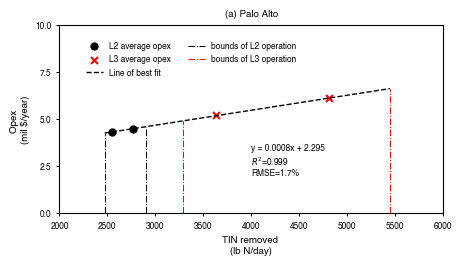

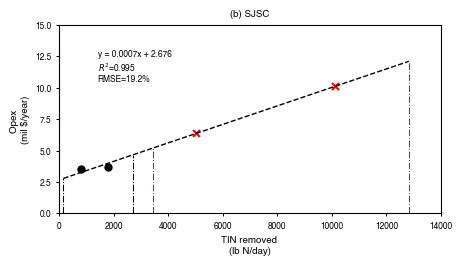

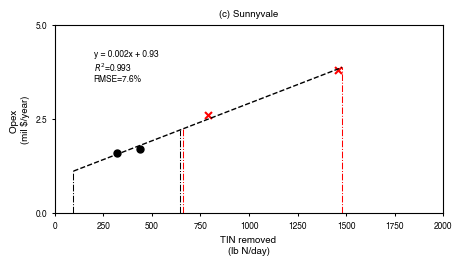

In [22]:
name = '/S9'

for i,WWTP in enumerate(LSB['Abbreviation']):
    plot_opex_WWTP(WWTP, i)

## Plot capital costs of upgrades in each WWTP

In [23]:
tags = ['BACWA_Current_conc',	'Average_TIN_Dry_BACWA_projected (lb N/day)',	'Average_Flow_Dry_BACWA_current',	'Average_Flow_Dry_BACWA_projected',
        'Opex_min_L2',	'Opex_max_L2',	'Opex_avg_dry_L2',	'Opex_avg_year_L2',	'Opex_dry_mil_L2',	'Opex_year_mil_L2',
        'Opex_min_L3',	'Opex_max_L3',	'Opex_avg_dry_L3',	'Opex_avg_year_L3',	'Opex_dry_mil_L3',	'Opex_year_mil_L3',
        'Capex_L2_LB_max',	'Capex_L2_UB_max',	'Capex_dry_mil_L2',	'Capex_year_mil_L2',
        'Capex_L3_LB_max',	'Capex_L3_UB_max',	'Capex_dry_mil_L3',	'Capex_year_mil_L3']


def plot_capex_WWTP(WWTP, i):
        df = LSB[LSB['Abbreviation'] == WWTP]
        # L2 tags
        opex_min_L2 = df[tags[4]]
        opex_max_L2 = df[tags[5]]
        opex_avg_L2 = [df[tags[6]], df[tags[7]]]
        opex_mil_L2 = [df[tags[8]], df[tags[9]]]
        capex_mil_L2 = [df[tags[18]], df[tags[19]]]

        # L3 tags
        opex_min_L3 = df[tags[10]]
        opex_max_L3 = df[tags[11]]
        opex_avg_L3 = [df[tags[12]], df[tags[13]]]
        opex_mil_L3 = [df[tags[14]], df[tags[15]]]
        capex_mil_L3 = [df[tags[22]], df[tags[23]]]

        # create figure
        fig, ax = plt.subplots(1,1, figsize=(80/25.4, 60/25.4))

        # plot data points
        plt.scatter(opex_avg_L2, capex_mil_L2, color='black', label='L2 capex', marker='o', s=15)
        plt.scatter(opex_avg_L3, capex_mil_L3, color='red', label='L3 capex', marker='x', s=15)
        plt.plot(opex_avg_L2, capex_mil_L2, color='black', linestyle='-', linewidth=line_wid)
        plt.plot(opex_avg_L3, capex_mil_L3, color='red', linestyle='-', linewidth=line_wid)
        
        
        ax.set_xlabel('Design capacity for TIN removal \n(lb N/day)', **hfont)
        ax.set_ylabel('Capex \n(mil $)', **hfont)
        ax.set_title(lab[i] + ' ' + WWTP, **hfont)
        min_x = math.floor(opex_min_L2.iloc[0]/ 2000) * 2000
        max_x = math.ceil(opex_max_L3.iloc[0] / 2000) * 2000
        ax.set_xlim(min_x, max_x)
        
        max_y = math.ceil(capex_mil_L3[1].item()/100)*100
        ax.set_ylim(0, max_y)
        ytck = [50, 150, 100]
        ax.set_yticks(np.arange(0, max_y+1, ytck[i]))

        
        ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid)

        if i == 0:
                ax.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.6, 0.3), prop={'family':'Helvetica', 'size':leg_size})
        fig.tight_layout()

        fig.savefig(file + '/SI' + name + lab[i][1] + '_' + WWTP + ".svg", format="svg", dpi=300)

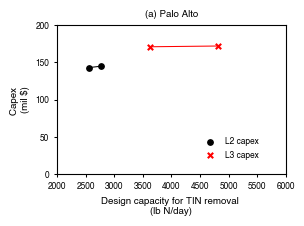

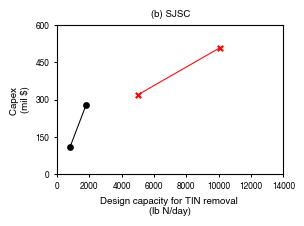

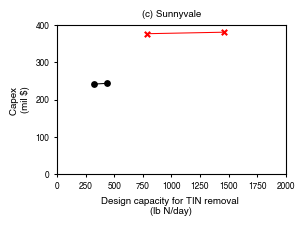

In [24]:
name = '/S11'

for i,WWTP in enumerate(LSB['Abbreviation']):
    plot_capex_WWTP(WWTP, i)

# Plot Opex Best Fit Line

In [25]:
# import path as dataframe
import pandas as pd
import numpy as np

name = '/S10'

path = '../Input_Data/Sidestream_opex_BACWA.csv'
df = pd.read_csv(path)

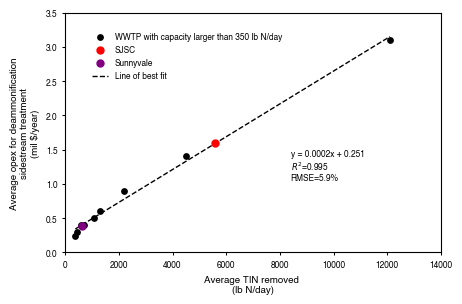

In [26]:
colors = {'L3': '#726DA8', 'L2': '#484538', 'SS': '#CAD49D', 'L2upg3': '#EB5E28'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2

abb = {'SJSC': 'San Jose-Santa Clara Regional Wastewater Facility ', 'Sunnyvale': 'City of Sunnyvale'}

# Select WWTPs with sidestream larger than 350 lb N/day
TN = df[df['TN_removal'] > 350].TN_removal 
opex = df[df['TN_removal'] > 350].Opex

# create figure
fig, ax = plt.subplots(1,1, figsize=(120/25.4, 80/25.4))

# plot data points
plt.scatter(TN, opex, color='black', label='WWTP with capacity larger than 350 lb N/day', marker='o', s=15, zorder=2.5)
plt.scatter(df[df.WWTP == abb['SJSC']].TN_removal, df[df.WWTP == abb['SJSC']].Opex, color='red', label='SJSC', marker='o', s=25, zorder=2.5)
plt.scatter(df[df.WWTP == abb['Sunnyvale']].TN_removal, df[df.WWTP == abb['Sunnyvale']].Opex, color='purple', label='Sunnyvale', marker='o', s=25, zorder=2.5)


# find best fit linear line 
# create new list that contains both opex_avg_L2 and opex_avg_L3
        
z = np.polyfit(TN, opex, 1)
p = np.poly1d(z)
plt.plot(TN, p(TN), color='black', linestyle='--', linewidth=1, label='Line of best fit')

#calculate R2
r2 = np.corrcoef(opex, p(TN))[0, 1]**2

#calculate RMSE
rmse = np.sqrt(np.mean((p(TN) - opex)**2))*100



ax.set_xlabel('Average TIN removed \n(lb N/day)', **hfont)
ax.set_ylabel('Average opex for deammonification\nsidestream treatment\n(mil $/year)', **hfont)
min_x = 0
max_x = 14000
ax.set_xlim(min_x, max_x)
ax.set_xticks(np.arange(0, max_x+1, 2000))

max_y = 3.5
ax.set_ylim(0, max_y)
ax.set_yticks(np.arange(0, max_y+0.1, 0.5))


x_scale = 1.2
y_scale = 0.3

# add equation for best fit line
text1 = 'y = ' + str(round(z[0], 4)) + 'x + ' + str(round(z[1], 3))
text2 = '$R^{2}$=%.3f'%r2
text3 = 'RMSE=%.1f'%rmse + '%'

plt.text((min_x + max_x)/2 * x_scale, max_y * y_scale, text1 + '\n' + text2 + '\n' + text3, fontsize=leg_size, color='black', fontfamily='Helvetica')



ax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
ax.tick_params(axis="both", width=line_wid, length=bord_wid)

ax.legend(loc='upper left', fontsize=10, frameon=False, bbox_to_anchor=(0.05, 0.95), prop={'family':'Helvetica', 'size':leg_size})
fig.tight_layout()

fig.savefig(file + '/SI' + name + ".svg", format="svg", dpi=300)